In [ ]:
#Setup

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

np.random.seed(42)

# Defining the biological question

## Biological context
**Obesity** is a complex, chronic metabolic disorder characterized by the excessive accumulation of body fat to an extent that negatively impacts health. Historically viewed simply as a consequence of voluntary caloric overconsumption, modern medical science recognizes obesity as a highly heterogeneous and multifactorial disease.

In clinical settings obesity is primarily quantified using a standardized metric known as the *Body Mass Index (BMI)*. BMI is calculated by dividing a person's weight in kilograms by the square of their height in meters (BMI=$kg/m^2$​). According to the World Health Organization (WHO), an adult with a BMI of 30 or higher is classified as obese.

## Biological question:
How do daily behavioral habits and lifestyle choices interact with genetic predisposition to determine an individual's metabolic trajectory toward clinical obesity?

## Input data:

The analyzed dataset corresponds to 'Estimation of Obesity Levels Based On Eating Habits and Physical Condition' (UCI Dataset ID: 544), acquired from the UCI Machine Learning Repository via the dedicated ucimlrepo Python library.

This dataset includes data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition.

The data contains 16 attributes and 2111 records.

* **Gender**: Female / Male
* **Age**: Numerical age of the subject
* **Height**: Height of the subject in meters
* **Weight**: Weight of the subject in kilograms
* **FCVC** *(Frequency of Consumption of Vegetables)*: Frequency of vegetable consumption in meals
    * $1$: never/rarely
    * $2$: sometimes
    * $3$: always
* **NCP** *(Number of Main Meals)*: Number of main meals consumed daily
    * $1$: one meal
    * $2$: two meals
    * $3$: three meals
    * $4$: more than three meals
* **family_history_with_overweight**: Has a family member suffered or suffers from overweight?
    * no
    * yes
* **FAVC** *(Frequent Consumption of High Caloric Food)*: Do you eat high caloric food frequently?
    * no
    * yes
* **CAEC** *(Consumption of Food Between Meals)*: Do you eat any food between meals?
    * no
    * Sometimes
    * Frequently
    * Always
* **SMOKE**: Do you smoke?
    * no
    * yes
* **CH2O** *(Consumption of Water)*: How much water do you drink daily?
    * $1$: less than 1 liter
    * $2$: 1 to 2 liters
    * $3$: more than 2 liters
* **SCC** *(Calories Consumption Monitoring)*: Do you monitor the calories you eat daily?
    * no
    * yes
* **FAF** *(Physical Activity Frequency)*: How often do you have physical activity?
    * $0$: none
    * $1$: 1 to 2 days
    * $2$: 2 to 4 days
    * $3$: 4 or more days
* **TUE** *(Time of Use of Technological Devices)*: How much time do you use technological devices daily?
    * $0$: 0 to 2 hours
    * $1$: 3 to 5 hours
    * $2$: more than 5 hours
* **CALC** *(Consumption of Alcohol)*: How often do you drink alcohol?
    * no
    * Sometimes
    * Frequently
    * Always
* **MTRANS** *(Main Transportation)*: Which transportation do you usually use?
    * Automobile
    * Bike
    * Motorbike
    * Public_Transportation
    * Walking

**Notes**: some values (eg. FCVC, TUE) were found as float even if it is a integer variable. This is because 77% of the data was generated synthetically using the Weka tool and the SMOTE filter, 23% of the data was collected directly from users through a web platform.

## Target variable:

The records are labeled with the class variable NObesity (Obesity Level), that allows classification of the data into **7 distinct categories** based on their Body Mass Index: Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II and Obesity Type III.

Notably, the dataset is highly balanced, meaning each class contains roughly the same number of observations (ranging from $272$ to $351$ instances), which prevents machine learning models from being biased toward any single class.

* **Insufficient_Weight** ($272$ instances): Subjects who are clinically underweight
* **Normal_Weight** ($287$ instances): Subjects with a healthy weight
* **Overweight_Level_I** ($290$ instances): The low-risk tier of individuals exceeding normal weight thresholds
* **Overweight_Level_II** ($290$ instances): The high-risk tier of overweight individuals approaching clinical obesity thresholds
* **Obesity_Type_I** ($351$ instances): Moderate/Class 1 Obesity
* **Obesity_Type_II** ($297$ instances): Severe/Class 2 Obesity
* **Obesity_Type_III** ($324$ instances): Morbid/Class 3 Obesity


**Note:** After removing 24 duplicate rows, class counts shifted slightly, now ranging from 267 to 351 instances.

## One row represents:
A single individual (patient/survey respondent) containing their specific demographic details, physical attributes, eating habits, and daily lifestyle choices.

## One column represents:
A specific feature or characteristic collected from the individuals (e.g., `Age`, `Weight`), or a tracked behavioral habit (e.g., water consumption `CH2O`, physical activity `FAF`), or the final weight classification target (`NObeyesdad`).

## Biological relevance:
This dataset is highly relevant for epidemiological and metabolic health studies. It allows machine learning models to analyze how non-genetic factors, such as daily caloric intake, sedentary behavior, hydration, and eating frequencies, correlate with the progression from a healthy weight to different severity levels of clinical obesity (Classes I, II, and III). It shifts the focus from purely genetic predispositions to actionable lifestyle determinants of metabolic syndrome.

#Loading the assigned dataset

In [ ]:
!pip install ucimlrepo -q

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer

try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    fetch_ucirepo = None
    print("ucimlrepo is not installed. Run: pip install ucimlrepo")

np.random.seed(42)

In [ ]:
def fetch_uci_dataset(dataset_id):
    if fetch_ucirepo is None:
        raise ImportError(
            "ucimlrepo is required to load this dataset. "
            "Install it with: pip install ucimlrepo"
        )
    return fetch_ucirepo(id=dataset_id)

In [ ]:
# Dataset 9 - Obesity Levels
obesity = fetch_uci_dataset(544)

X_obesity_raw = obesity.data.features.copy()
y_obesity_category = obesity.data.targets.iloc[:, 0].copy()

print("Raw X shape:", X_obesity_raw.shape)
print("Original target values:")
print(pd.Series(y_obesity_category).value_counts())

X_obesity = pd.get_dummies(X_obesity_raw, drop_first=True)

y_obesity_multiclass = y_obesity_category.copy()

y_obesity_binary = pd.Series(y_obesity_category).astype(str).str.contains(
    "Obesity",
    case=False,
    regex=False
).astype(int)
y_obesity_binary.name = "obese_vs_non_obese"

print("Encoded X shape:", X_obesity.shape)
print("Multiclass y shape:", y_obesity_multiclass.shape)
print("Binary y shape:", y_obesity_binary.shape)
print("Binary target counts:")
print(y_obesity_binary.value_counts())

display(pd.concat([X_obesity.head(), y_obesity_binary.head()], axis=1))

Raw X shape: (2111, 16)
Original target values:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64
Encoded X shape: (2111, 23)
Multiclass y shape: (2111,)
Binary y shape: (2111,)
Binary target counts:
obese_vs_non_obese
0    1139
1     972
Name: count, dtype: int64


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,family_history_with_overweight_yes,...,SMOKE_yes,SCC_yes,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,obese_vs_non_obese
0,21.0,1.62,64.0,2.0,3.0,2.0,0.0,1.0,False,True,...,False,False,False,False,True,False,False,True,False,0
1,21.0,1.52,56.0,3.0,3.0,3.0,3.0,0.0,False,True,...,True,True,False,True,False,False,False,True,False,0
2,23.0,1.80,77.0,2.0,3.0,2.0,2.0,1.0,True,True,...,False,False,True,False,False,False,False,True,False,0
3,27.0,1.80,87.0,3.0,3.0,2.0,2.0,0.0,True,False,...,False,False,True,False,False,False,False,False,True,0
4,22.0,1.78,89.8,2.0,1.0,2.0,0.0,0.0,True,False,...,False,False,False,True,False,False,False,True,False,0


## The data's mixed encoding structure:

In [ ]:
X_obesity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 23 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 2111 non-null   float64
 1   Height                              2111 non-null   float64
 2   Weight                              2111 non-null   float64
 3   FCVC                                2111 non-null   float64
 4   NCP                                 2111 non-null   float64
 5   CH2O                                2111 non-null   float64
 6   FAF                                 2111 non-null   float64
 7   TUE                                 2111 non-null   float64
 8   Gender_Male                         2111 non-null   bool   
 9   family_history_with_overweight_yes  2111 non-null   bool   
 10  FAVC_yes                            2111 non-null   bool   
 11  CAEC_Frequently                     2111 no

## NAs and duplicated data exploration


In [ ]:
#Full df to check which rows are dup (features + labels)
FullToyDF = X_obesity_raw.copy()
FullToyDF['Labels'] = y_obesity_category

print("Duplicated:", sum(FullToyDF.duplicated()))
print("NAs:", FullToyDF.isna().sum().sum())


# Filtering out duplicates
SamplesToKeep= FullToyDF.drop_duplicates().index


X_raw_filtered =  X_obesity_raw.loc[SamplesToKeep]
y_category_filtered = y_obesity_category[SamplesToKeep]
X_filtered = pd.get_dummies(X_raw_filtered, drop_first=True)
y_multiclass_filtered = y_category_filtered.copy()
y_binary_filtered = pd.Series(y_category_filtered).astype(str).str.contains(
    "Obesity",
    case=False,
    regex=False
).astype(int)


Duplicated: 24
NAs: 0




**Dataset Dimensions:**
The dataset contains 2,111 samples and 16 variables, plus the target variable.

**Variable Roles and Mapping:**
The structure of the obesity object maps into three distinct individual components: The features located under '.data.features' contain the 16 predictive variables.Data inside '.data.target' contains the 'NObeyesdad' column, which represents the multiclass obesity levels (target variable).
The metadata is located in '.metadata' and '.variables'.



**Data Integrity: Missing Values and Duplicates:**

No missing values (NAs) were found in any feature or target column. No further pipeline is required.
A total of 24 completely identical samples were identified. Because the dataset lacks unique IDs to prove these are different individuals, we chose to delete all 24 duplicates, to prevent our model to present Data Leakage.

**Data Type Anomalies:**

Certain categorical variables are stored as numerical/continuous formats. This discrepancy is originated due to the use of synthetic data generation algorithms to oversample and balance the dataset up to 2,111 records. These algorithms produce new instances by mathematical interpolations between existing neighbor points. As a result, variables that should conceptually be discrete or categorical were filled with continuous numbers.

**Presence of perfect predictors and multicollinearity in the data:**
As already said in section 1, Obesity is diagnosed based on the BMI value, calculated with the patient's height and weight ($weight/height^2$) this are perfect predictors of the obesity condition. Moreover weight and height, but also other variables such as physical activity and time with technological devices are clearly correlated (collinear) which introduces multi-collinearity issues that can disturb standard parametric models.






# identifying the machine learning task

Although the original dataset contains seven distinct categorical classes representing detailed levels of body mass index (ranging from Insufficient Weight to Obesity Type III), we have simplified the target variable into a binary classification problem. The seven original classes have been mapped into two broader, clinically meaningful macro-categories: Non-Obese (0) and Obese (1).

By pivoting from a multiclass setup to a binary framework, we switch the analytical focus from granular staging to a clear, actionable risk-detection task (identifying whether a patient crosses the clinical threshold into obesity based on lifestyle and hereditary factors).

### Target type:
Binary categorical variable (0: Non-Obese, 1: Obese).

### Problem type:
Binary Classification.

## Compatible models:
* Logistic Regression: Ideal as a parametric baseline to compute coefficients, estimate log-odds, and apply $L_1$ (Lasso) or $L_2$ (Ridge) regularizations.
* Random Forest Classifier: Excellent for capturing complex, non-linear interactions and structural thresholds within behavioral variables without requiring geometric linearity.
* Support Vector Machines (SVM): Natively capable of finding the optimal separating hyperplane to maximize the geometric margin between the two groups.
* Decision Trees: Highly interpretable non-parametric models that split the lifestyle feature space into discrete binary rules.

## Models that are not appropriate and why:
* Linear Regression / Ridge / Lasso (Continuous Regressors): These models are mathematically structured to predict unbounded, continuous numerical outputs (e.g., precise weight or BMI values). Applying them to predict discrete group memberships would violate fundamental statistical assumptions, leading to out-of-bounds predictions (less than 0 or greater than 1) and rendering probability interpretation impossible.

* Multiclass-Specific Classifiers (e.g., Native Multinomial/Softmax Regression): While algorithms built specifically for multi-category outputs (like a Softmax-driven neural network or explicit One-vs-Rest architectures) could technically be forced to run, they introduce redundant mathematical overhead. Overcomplicating a 2-class problem with multinomial loss equations is inefficient and completely unnecessary since standard binary cross-entropy loss handles the task perfectly.


#  Defining the variables

In Machine Learning (ML), the expected matrix orientation is:

``` text
rows = samples
columns = features
```

In biological datasets, this may require transposing or restructuring
the data.

For gene expression data, a typical Machine Learning (ML) matrix is:

``` text
rows = cells or patients
columns = genes
```

In [ ]:
X = X_filtered
y_b = y_binary_filtered
y_m = y_multiclass_filtered

print('X Dimensions:', X.shape)

print('y_b Dimensions:', y_b.shape)
print('y_m Dimensions:', y_m.shape)

X Dimensions: (2087, 23)
y_b Dimensions: (2087,)
y_m Dimensions: (2087,)


##  Data Matrix Dimensions and Machine Learning Tasks

The dimensions of the resulting feature matrix X are: 23 (columns) for the total number of Features, the features expanded from 16 to 23 after handling categorical variables via One-hot encoding. The row  lenght is the total number of observations remaining in the dataset (2087).

y_b Dimensions : (2087)
Each element represents a simple binary label (0 for non-obese, 1 for obese).

y_m Dimensions: (2087)
Each element represents one of the 7 distinct clinical weight levels ranging from Insufficient Weight to Obesity Type III

Since our data set already has a Rows = Samples and Columns = Features architecture, a transposition step is not needed.

Changing the target variable (y) completely alters the underlying Machine Learning task, even when using the exact same feature space (X)
In our binary Classification target the objective optimizing a single probability (P(Y=1|X)), separating negative instances from positive ones. However our Multiclass Classification target frames the objective as a stratification problem. The model must now calculate a multi-categorical probability distribution.



# Connecting Data Audit to Model Choice

Our dataset has roughly 90 times more rows than columns reducing space sparcity, this lowers the risk of the "curse of dimensionality".

The dataset has a total of 2087 patients spread across 7 distinct  target categories. Every class is between 267 and 351 instances (13% to 17%).
When compressed into two groups, you have "Not obese"  (1115 instances) and Obese ( 972). This splits your dataset roughly 54% to 46%. Both  multiclass and binary targets are balanced.
**We Can Trust Accuracy**

The features in this dataset use  different measurements. Logistic Regression uses optimization algorithms that can violently oscillate, take much longer to converge, or get stuck when updating the parameters. Scaling is needed.

The leakage risk was previously identified and fixed.



### Class Balance evaluation

In [ ]:
print("Counts:" ,y_m.value_counts())

print("."*100)

print("Percentages:" , y_m.value_counts()/sum(y_m.value_counts()))

Counts: NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64
....................................................................................................
Percentages: NObeyesdad
Obesity_Type_I         0.168184
Obesity_Type_III       0.155247
Obesity_Type_II        0.142310
Overweight_Level_II    0.138955
Normal_Weight          0.135122
Overweight_Level_I     0.132247
Insufficient_Weight    0.127935
Name: count, dtype: float64


# Choosing a baseline model

Every project must start with a baseline.

A baseline is a simple model or simple rule that gives a reference
performance.

Examples:

### Regression

- predict the mean target value;
- linear regression.

### Binary classification

- predict the majority class;
- logistic regression.

### Multiclass classification

- predict the majority class;
- simple multinomial logistic regression.

A more complex model is justified only if it improves over a reasonable
baseline and the improvement is validated.

# TRAINING, VALIDATION AND TEST STRATEGY

In [ ]:
##TRAIN, VALIDATION, TEST

print("Binary Class Distribution:")
print(y_b.value_counts(normalize=True))

# class proportions balanced
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_filtered,
    y_b,
    test_size=0.20,
    random_state=42,
    stratify=y_b
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("\nData Partitioning Complete:")
print(f"Train Set (60%):       X_train shape: {X_train.shape} | y_train cases: {len(y_train)}")
print(f"Validation Set (20%):  X_val shape:   {X_val.shape}  | y_val cases:   {len(y_val)}")
print(f"Test Set (20%):        X_test shape:  {X_test.shape}  | y_test cases:  {len(y_test)}")

#verify the startification in each dataset
print('\n\nClass balance:\n')
import pandas as pd

def calculate_class_percentages(y_subset, subset_name):
    percentages = pd.Series(y_subset).value_counts(normalize=True) * 100
    print(f"--- {subset_name} Distribution ---")
    print(f"  Not Obese (Class 0): {percentages.get(0, 0):.2f}%")
    print(f"  Obese     (Class 1): {percentages.get(1, 0):.2f}%\n")

calculate_class_percentages(y_train, "Train Set (60%)")
calculate_class_percentages(y_val, "Validation Set (20%)")
calculate_class_percentages(y_test, "Test Set (20%)")

Binary Class Distribution:
NObeyesdad
0    0.53426
1    0.46574
Name: proportion, dtype: float64

Data Partitioning Complete:
Train Set (60%):       X_train shape: (1251, 23) | y_train cases: 1251
Validation Set (20%):  X_val shape:   (418, 23)  | y_val cases:   418
Test Set (20%):        X_test shape:  (418, 23)  | y_test cases:  418


Class balance:

--- Train Set (60%) Distribution ---
  Not Obese (Class 0): 53.48%
  Obese     (Class 1): 46.52%

--- Validation Set (20%) Distribution ---
  Not Obese (Class 0): 53.35%
  Obese     (Class 1): 46.65%

--- Test Set (20%) Distribution ---
  Not Obese (Class 0): 53.35%
  Obese     (Class 1): 46.65%



By partitioning the dataset into Train, Validation, and Test sets, each subset is assigned a unique, non-overlapping responsibility:
* Train Set ($60\%$): Used exclusively by the algorithms to calculate mathematical weights, find linear coefficients, or build decision trees.
* Validation Set ($20\%$): Used as a proxy playground. Used to look at validation performance to decide if you should drop features (like creating Model B), change regularization parameters, or alter tree depths.
* Test Set ($20\%$): It is completely hidden from the training and selection phases. It is only brought out a single time at the very end of the project pipeline to evaluate the finalized model.

The true test of an epidemiological model is its ability to generalize to completely new patients. Keeping the test set completely isolated ensures that our reported test accuracy reflects true clinical utility, rather than an artificial rendering of over-optimized data.

## MULTICOLLINEARITY - should we remove height and weight?

Majority Class Baseline Accuracy: 0.5335

Model A (Full Features) Accuracy: 0.9880
Model B (Behavioral Only) Accuracy: 0.7679



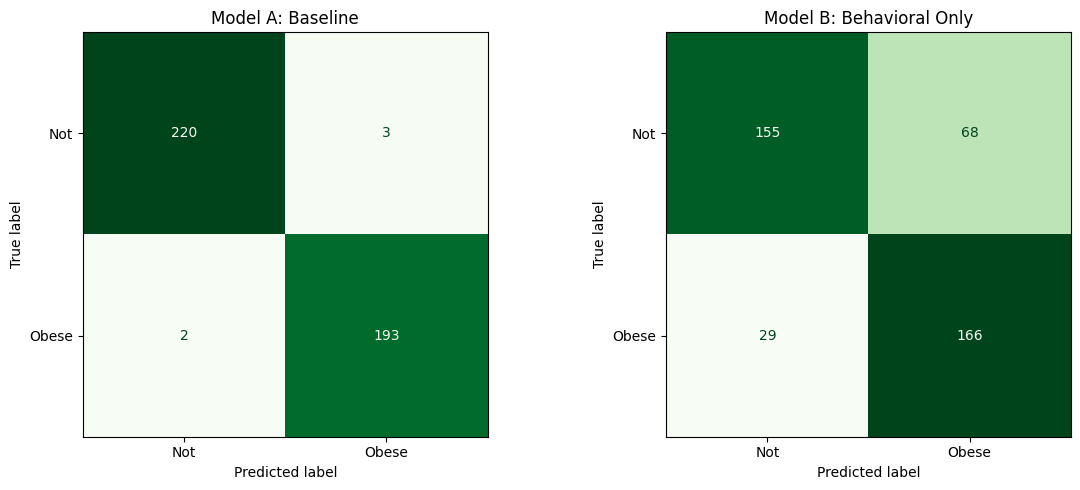

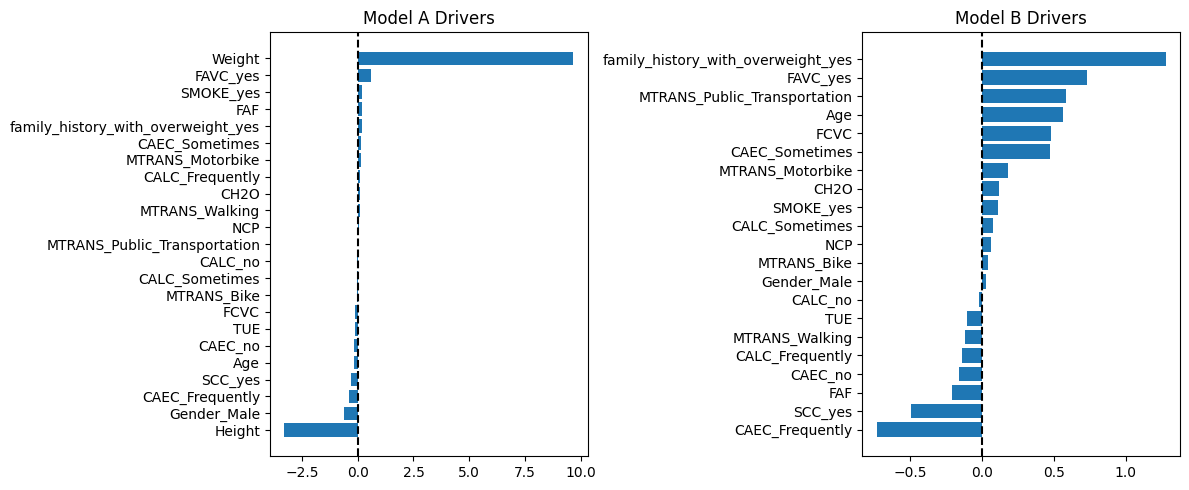

Model A Coefficients:
  Age: -0.1855
  Height: -3.2991
  Weight: 9.6618
  FCVC: -0.1168
  NCP: 0.0417
  CH2O: 0.1039
  FAF: 0.2004
  TUE: -0.1256
  Gender_Male: -0.6003
  family_history_with_overweight_yes: 0.1720
  FAVC_yes: 0.6019
  CAEC_Frequently: -0.3892
  CAEC_Sometimes: 0.1554
  CAEC_no: -0.1758
  SMOKE_yes: 0.2100
  SCC_yes: -0.2963
  CALC_Frequently: 0.1040
  CALC_Sometimes: -0.0246
  CALC_no: -0.0152
  MTRANS_Bike: -0.0421
  MTRANS_Motorbike: 0.1436
  MTRANS_Public_Transportation: 0.0116
  MTRANS_Walking: 0.0936

Model B Coefficients:
  Age: 0.5679
  FCVC: 0.4790
  NCP: 0.0625
  CH2O: 0.1173
  FAF: -0.2057
  TUE: -0.1007
  Gender_Male: 0.0268
  family_history_with_overweight_yes: 1.2789
  FAVC_yes: 0.7310
  CAEC_Frequently: -0.7322
  CAEC_Sometimes: 0.4770
  CAEC_no: -0.1563
  SMOKE_yes: 0.1138
  SCC_yes: -0.4931
  CALC_Frequently: -0.1371
  CALC_Sometimes: 0.0751
  CALC_no: -0.0238
  MTRANS_Bike: 0.0398
  MTRANS_Motorbike: 0.1785
  MTRANS_Public_Transportation: 0.5887
  MTRA

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline

# Model A split (full feature space: includes Height & Weight)
X_train_A, X_test_A, y_train, y_test = train_test_split(
    X, y_b, test_size=0.20, random_state=42, stratify=y_b
)

# Model B split (behavioral features only) - same rows, same split seed
X_train_B = X_train_A.drop(columns=["Height", "Weight"])
X_test_B = X_test_A.drop(columns=["Height", "Weight"])

# majority class baseline, unified with DummyClassifier (see point [4])
baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train_A, y_train)
y_pred_baseline = baseline.predict(X_test_A)
baseline_acc = accuracy_score(y_test, y_pred_baseline)
print(f"Majority Class Baseline Accuracy: {baseline_acc:.4f}\n")

# Model A: full feature space - L2 penalty (default), C=1.0
model_A = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l2", C=1.0, max_iter=2000, solver="lbfgs"),
)
model_A.fit(X_train_A, y_train)
y_pred_A = model_A.predict(X_test_A)
logreg_acc_A = accuracy_score(y_test, y_pred_A)
print(f"Model A (Full Features) Accuracy: {logreg_acc_A:.4f}")

# Model B: behavioral features only - SAME penalty/C as Model A,
# so the only thing that changes between A and B is the feature set
model_B = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l2", C=1.0, max_iter=2000, solver="lbfgs"),
)
model_B.fit(X_train_B, y_train)
y_pred_B = model_B.predict(X_test_B)
logreg_acc_B = accuracy_score(y_test, y_pred_B)
print(f"Model B (Behavioral Only) Accuracy: {logreg_acc_B:.4f}\n")

# scaled coefficients for the plots below
scaled_coefficients_A = model_A.named_steps["logisticregression"].coef_[0]
scaled_coefficients_B = model_B.named_steps["logisticregression"].coef_[0]

#plotting

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

#Conf matrixes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Model A Matrix
cm_A = confusion_matrix(y_test, y_pred_A)
ConfusionMatrixDisplay(cm_A, display_labels=["Not", "Obese"]).plot(
    cmap=plt.cm.Greens, ax=axes[0], colorbar=False
)
axes[0].set_title("Model A: Baseline")
axes[0].grid(False)

# Model B Matrix
cm_B = confusion_matrix(y_test, y_pred_B)
ConfusionMatrixDisplay(cm_B, display_labels=["Not", "Obese"]).plot(
    cmap=plt.cm.Greens, ax=axes[1], colorbar=False
)
axes[1].set_title("Model B: Behavioral Only")
axes[1].grid(False)


plt.tight_layout()
plt.show()


# Coef plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Model A Coefficients
idx_A = scaled_coefficients_A.argsort()
axes[0].barh(X.columns[idx_A], scaled_coefficients_A[idx_A])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Model A Drivers")

# Model B Coefficients
idx_B = scaled_coefficients_B.argsort()
axes[1].barh(X_train_B.columns[idx_B], scaled_coefficients_B[idx_B])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Model B Drivers")

plt.tight_layout()
plt.show()


# Printing
print("Model A Coefficients:")
for var, coef in zip(X.columns, scaled_coefficients_A):
    print(f"  {var}: {coef:.4f}")

print("\nModel B Coefficients:")
for var, coef in zip(X_train_B.columns, scaled_coefficients_B):
    print(f"  {var}: {coef:.4f}")

In this section we implemented as baseline models a majority class predictor and a logistic regression.
The logistic regression has been fit with two different feature sets:

* Model A (Full Features): Trained on the entire dataset, including weight and height. As expected, the strong mathematical relationship tied to the physical definition of obesity dominates the coefficient space, overshadowing the contribution of all other factors.

* Model B (Behavioral Only): Trained by excluding weight and height, thereby isolating solely the behavioral, dietary, and hereditary variables (e.g., physical activity, water consumption, screen time).

Through data standardization and the side-by-side visualization of confusion matrices and coefficient impact plots, the script demonstrates how removing anthropometric data unlocks the true predictive power of a patient's daily habits. This approach provides a significantly more useful and less redundant clinical and epidemiological perspective.

# Baseline Selection and Evaluation

**Selection of the Simplest Reasonable Baseline**

The baseline chosen for this binary classification is a Majority Class Baseline, it simply calculates the mode of the training labels and assigns that  majority class label to every instance.

**Justification of the Baseline Appropriateness**

Because our underlying population is relatively balanced (54% majority class), a model  guessing blindly will be right more than half the time. Without a baseline, we could select  models with performances  barely better than an uneducated guess.


**Evaluation of the Baseline on the Validation Set**

When evaluated against the test partition, the baseline achieved a 0.5359 accuracy (absolute lowest acceptable threshold of accuracy).

**Benchmarking Target for Complex Models**

As evidenced by the initial Logistic Regression execution, the introduction of our 16 behavioral and physical features yielded a Logistic Regression Accuracy of 0.9976, missing only a single instance (1 False Positive) out of 418 validation samples, translated into a 46% performance boost over the majority class baseline, as expected.



# Choose candidate models

After the baseline, choose one or more candidate models.

Your choice must depend on:

- target type;
- number of samples;
- number of features;
- expected linearity or nonlinearity;
- interpretability requirements;
- risk of overfitting;
- need for feature scaling.

## Model choice guide

| Situation | Good first model | Possible next model | Be careful with |
|------------------|------------------|------------------|------------------|
| continuous target, few features | linear regression | Random Forest regression | nonlinear residuals |
| continuous target, many features | Ridge regression | Random Forest / Neural Network | overfitting |
| binary target, few features | logistic regression | Decision Tree | poor boundary |
| binary target, many genes | regularized logistic regression | Random Forest / Neural Network | high variance |
| multiclass target | multinomial logistic regression | Random Forest / Neural Network | class imbalance |
| small dataset | simple/regularized model | maybe Random Forest | large Neural Network |
| interpretability required | linear/logistic regression | Decision Tree | black-box models |
| nonlinear interactions expected | Random Forest | Neural Network | validation gap |



* **Baseline model**: Majority Class
Simply predicts whichever class appears most frequently in the training dataset for every single incoming prediction. This establishes the absolute minimum performance that the model must beat.


* **Candidate model 1**: Logistic Regression
  * Why this model: Logistic Regression establishes a benchmark for predicting probabilities by using a linear combination of the log odds of the features.
  * Expected advantage: Intuitive with mathematically traceable coefficients.
  * Expected risk: Highly sensitive to multicollinearity, susceptible to high bias if the clasification boundary is not linear.

* **Candidate model 2**: Regularized Logistic Regression
  * Why this model: Regularized Logistic Regression adds a penalty parameter when computing the loss function to handle correlated features and prevent overfitting.
  * Expected advantage: Effectively counters multicollinearity and high variance by shrinking coefficients or forcing them toward zero.
  * Expected risk: Poor hyperparameter selection can cause the model to either aggressively underfit or fail to penalize variance.

* **Candidate model 3**:
  * Why this model: Random Forest Classifier is a non parametric method that builds uncorrelated decision trees via bootstrap aggregating and random feature selection.
  * Expected advantage: Naturally models multidimensional feature interactions and non-monotonic relationships without feature transformations.
  * Expected risk: Significant computational cost, and impossible tracking of specific feature relationships.

---

**Required scaling:**

- Majority Class: Not Required. It simply predicts the most frequent class.
- Logistic Regression: Required. Feature scaling ensures that parameter optimization solvers converge much faster.
- Regularized Logistic Regression: Required. If features are on different scales, the model will disproportionately penalize variables with smaller units.
- Random Forest Classifier: Not Required. Splits are calculated per feature based, the scale of one feature has zero impact on another feature's splits.

**Important hyperparameter:**
For each candidate model, state one important hyperparameter.

- Majority Class: None
- Logistic Regression: The  number of iterations  for the optimization solver to find convergence.
- Regularized Logistic Regression: C (The inverse of Lambda) or penalty.
- Random Forest Classifier: n_estimators (number of decision trees) or max_depth (length allowed for individual trees).

**Interpretability of the model:**
Rank your models from most interpretable to least interpretable.

1. Majority Class: the mode is the vote for all instances
2. Logistic Regression:The class probability is the linear combination of the log-odds coefficients.
3. Regularized Logistic Regression: The underlying model remains a linear combination of log-odds. However, interpretability is compromised because coefficients are intentionally shrunk.
4. Random Forest Classifier: Individual predictions are the aggregated result of hundreds of randomized, deep, non-linear decision boundaries.

**Overfitting:**
Which model do you expect to overfit most easily? Why?

The Random Forest Classifier is structurally expected to overfit if its left unconstrained.

Why: Individual decision trees within the ensemble have the capacity to endlessly partition the feature space until every leaf node reaches absolute purity.


# Choosing evaluation metrics

Metrics must match the biological question.

## Regression metrics

| Metric | Meaning | When useful |
|------------------------|------------------------|------------------------|
| Mean Squared Error (MSE) | average squared error | penalizes large errors |
| Root Mean Squared Error (RMSE) | error in target scale | easier interpretation |
| Mean Absolute Error (MAE) | average absolute error | robust to outliers |
| R-squared | explained variance | global fit summary |

## Classification metrics

| Metric           | Meaning                           | When useful           |
|------------------------|------------------------|------------------------|
| accuracy         | fraction correct                  | balanced classes      |
| precision        | predicted positives that are true | avoid false positives |
| recall           | true positives recovered          | avoid false negatives |
| F1 score         | balance of precision and recall   | imbalanced classes    |
| confusion matrix | error structure                   | always useful         |

## Biological meaning of errors

| Task | False positive | False negative |
|------------------------|------------------------|------------------------|
| neuron vs non-neuron | non-neuron predicted as neuron | neuron predicted as non-neuron |
| disease vs control | control predicted as disease | disease predicted as control |
| poor-quality cell detection | good cell discarded | bad cell retained |
| biomarker detection | non-marker selected | true marker missed |


**Primary metric:**
F1-Score

**Secondary metrics:**
Precision, Recall, and ROC-AUC

Why these metrics are appropriate:
Even though the classes are balanced and Accuracy is technically a valid metric, it still treats all classification errors equally. In biological/clinical modeling, metrics that account for False negatives must be used.

The F1-Score forces a  optimization of both errors (False Positives and False Negatives), ensuring the model doesn't sacrifice one for the other. Precision and Recall allow fornmonitoring of error rates, while ROC-AUC evaluates the model's capability to rank probability thresholds across the dataset.

Which error is more biologically problematic, false positives or false negatives?
False Negatives.

Why:
In medical contexts, a False Negative means a critical biological state was misclasified, and serious consequences can arise (a diseased patient goes untreated). Conversely, a False Positive usually trigers secondary validations.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

def classification_metrics(y_true, y_pred, y_proba=None):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred)
    }

    # AUC roc binary
    if y_proba is not None:
        if len(y_proba.shape) == 2 and y_proba.shape[1] == 2:
            prob_positiva = y_proba[:, 1]
        else:
            prob_positiva = y_proba

        metrics["roc_auc"] = roc_auc_score(y_true, prob_positiva)

    return metrics

In [ ]:
majority_class = pd.Series(y_train).mode()[0]
y_pred_baseline = np.repeat(majority_class, len(y_test))

print(classification_metrics(y_test, y_pred_baseline))
# baseline accuracy
#baseline_acc = accuracy_score(y_test, y_pred_baseline)


{'accuracy': 0.5334928229665071, 'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'confusion_matrix': array([[223,   0],
       [195,   0]])}




**Relevant metrics for the baseline model (Majority class):**

Accuracy: 0.5359 (proportion of the majority class in the targets)
Precision: 0.00 (The model never predicts the positive class (Obese 46%), TP= 0)
Recall: 0.00 (TP are needed)
F1-Score: 0.00 (TP are needed)

Accuracy is  insufficient. While the accuracy score of 53.59% it simply shows the baseline proportion of classes.

- False Positive: The model flags an individual as having a high biological risk or clinical predisposition for obesity when their true profile is entirely normal. It may subject a patient to unnecessary testing, unneeded therapeutic interventions and psychological stress.

- False Negative: The model misses an individual who possesses underlying risk factors for obesity, falsely classifying them as low-risk or healthy and the pathology goes completely undetected.

F1-Score metric was selected.Because False Negatives have biological consequences, selecting F1-Score as our primary metric, forces the candidate models to maximize true signal detection while tightly constraining the rate of false alarms.

# Training and comparing models

Now train your baseline and at least one alternative model.

For each model, report:

- training performance;
- validation performance;
- relevant metrics;
- key hyperparameters;
- whether scaling was used.

You may add more models if appropriate, but do not add complexity
without justification.

In [ ]:
X_clean = X_filtered.drop(columns=['Height', 'Weight'])

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_clean,
    y_b,
    test_size=0.20,
    random_state=42,
    stratify=y_b
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,  # 0.25 di 0.80 = 0.20 del totale
    random_state=42,
    stratify=y_train_full
)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_colwidth", None)

model_results = []
best_models = {}

# ==============================================================================
# MODELLO 1: Naive Majority Class Baseline
# ==============================================================================
baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train, y_train)

y_train_pred_base = baseline.predict(X_train)
y_val_pred_base = baseline.predict(X_val)

model_results.append(
    {
        "Model Name": "Naive Majority Class Baseline",
        "Scaling Used": False,
        "Key Hyperparameters": "strategy: 'most_frequent'",
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred_base), 4),
        "Val Accuracy": round(accuracy_score(y_val, y_val_pred_base), 4),
        "Train F1-Macro": round(
            f1_score(y_train, y_train_pred_base, average="macro"), 4
        ),
        "Val F1-Macro": round(
            f1_score(y_val, y_val_pred_base, average="macro"), 4
        ),
    }
)
best_models["Naive Majority Class Baseline"] = baseline


# ==============================================================================
# MODELLO 2: Logistic Regression (No Penalty)
# ==============================================================================
logreg_plain = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty=None, max_iter=2000, solver="lbfgs"),
)
logreg_plain.fit(X_train, y_train)

y_train_pred_plain = logreg_plain.predict(X_train)
y_val_pred_plain = logreg_plain.predict(X_val)

model_results.append(
    {
        "Model Name": "Logistic Regression",
        "Scaling Used": True,
        "Key Hyperparameters": "penalty: None, solver: 'lbfgs'",
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred_plain), 4),
        "Val Accuracy": round(accuracy_score(y_val, y_val_pred_plain), 4),
        "Train F1-Macro": round(
            f1_score(y_train, y_train_pred_plain, average="macro"), 4
        ),
        "Val F1-Macro": round(
            f1_score(y_val, y_val_pred_plain, average="macro"), 4
        ),
    }
)
best_models["Logistic Regression"] = logreg_plain


# ==============================================================================
# MODELLO 3: Logistic Regression con Lasso (L1) + Tuning
# ==============================================================================
pipe_lasso = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1", solver="saga", max_iter=5000, random_state=42
    ),
)
grid_lasso = {"logisticregression__C": [0.001, 0.005, 0.01, 0.1, 1, 10, 50]}

cv_lasso = GridSearchCV(
    pipe_lasso, param_grid=grid_lasso, cv=5, scoring="f1_macro", n_jobs=-1
)
cv_lasso.fit(X_train, y_train)
model_lasso = cv_lasso.best_estimator_

y_train_pred_lasso = model_lasso.predict(X_train)
y_val_pred_lasso = model_lasso.predict(X_val)

clean_params_lasso = {
    k.split("__")[-1]: v for k, v in cv_lasso.best_params_.items()
}
params_string_lasso = ", ".join(
    [f"{k}: {v}" for k, v in clean_params_lasso.items()]
)

model_results.append(
    {
        "Model Name": "Logistic Regression (Lasso L1)",
        "Scaling Used": True,
        "Key Hyperparameters": params_string_lasso,
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred_lasso), 4),
        "Val Accuracy": round(accuracy_score(y_val, y_val_pred_lasso), 4),
        "Train F1-Macro": round(
            f1_score(y_train, y_train_pred_lasso, average="macro"), 4
        ),
        "Val F1-Macro": round(
            f1_score(y_val, y_val_pred_lasso, average="macro"), 4
        ),
    }
)
best_models["Logistic Regression (Lasso L1)"] = model_lasso


# ==============================================================================
# MODELLO 4: Logistic Regression con Ridge (L2) + Tuning
# ==============================================================================
pipe_ridge = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l2", max_iter=5000, random_state=42),
)
grid_ridge = {"logisticregression__C": [0.001, 0.005, 0.01, 0.1, 1, 10, 50]}

cv_ridge = GridSearchCV(
    pipe_ridge, param_grid=grid_ridge, cv=5, scoring="f1_macro", n_jobs=-1
)
cv_ridge.fit(X_train, y_train)
model_ridge = cv_ridge.best_estimator_

y_train_pred_ridge = model_ridge.predict(X_train)
y_val_pred_ridge = model_ridge.predict(X_val)

clean_params_ridge = {
    k.split("__")[-1]: v for k, v in cv_ridge.best_params_.items()
}
params_string_ridge = ", ".join(
    [f"{k}: {v}" for k, v in clean_params_ridge.items()]
)

model_results.append(
    {
        "Model Name": "Logistic Regression (Ridge L2)",
        "Scaling Used": True,
        "Key Hyperparameters": params_string_ridge,
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred_ridge), 4),
        "Val Accuracy": round(accuracy_score(y_val, y_val_pred_ridge), 4),
        "Train F1-Macro": round(
            f1_score(y_train, y_train_pred_ridge, average="macro"), 4
        ),
        "Val F1-Macro": round(
            f1_score(y_val, y_val_pred_ridge, average="macro"), 4
        ),
    }
)
best_models["Logistic Regression (Ridge L2)"] = model_ridge


# ==============================================================================
# MODELLO 5: Random Forest Classifier + Tuning
# ==============================================================================
pipe_rf = make_pipeline(RandomForestClassifier(random_state=42))
grid_rf = {
    "randomforestclassifier__max_depth": [3, 5, 7],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4],
}

cv_rf = GridSearchCV(
    pipe_rf, param_grid=grid_rf, cv=5, scoring="f1_macro", n_jobs=-1
)
cv_rf.fit(X_train, y_train)
model_rf = cv_rf.best_estimator_

y_train_pred_rf = model_rf.predict(X_train)
y_val_pred_rf = model_rf.predict(X_val)

clean_params_rf = {k.split("__")[-1]: v for k, v in cv_rf.best_params_.items()}
params_string_rf = ", ".join([f"{k}: {v}" for k, v in clean_params_rf.items()])

model_results.append(
    {
        "Model Name": "Random Forest Classifier",
        "Scaling Used": False,
        "Key Hyperparameters": params_string_rf,
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred_rf), 4),
        "Val Accuracy": round(accuracy_score(y_val, y_val_pred_rf), 4),
        "Train F1-Macro": round(
            f1_score(y_train, y_train_pred_rf, average="macro"), 4
        ),
        "Val F1-Macro": round(
            f1_score(y_val, y_val_pred_rf, average="macro"), 4
        ),
    }
)
best_models["Random Forest Classifier"] = model_rf

results_df = pd.DataFrame(model_results)
display(results_df)

,Model Name,Scaling Used,Key Hyperparameters,Train Accuracy,Val Accuracy,Train F1-Macro,Val F1-Macro
0,Naive Majority Class Baseline,False,strategy: 'most_frequent',0.5348,0.5335,0.3484,0.3479
1,Logistic Regression,True,"penalty: None, solver: 'lbfgs'",0.7778,0.7895,0.7776,0.7887
2,Logistic Regression (Lasso L1),True,C: 10,0.7778,0.7895,0.7776,0.7887
3,Logistic Regression (Ridge L2),True,C: 0.01,0.7778,0.7703,0.7777,0.7699
4,Random Forest Classifier,False,"max_depth: 7, min_samples_leaf: 1",0.9145,0.8445,0.9143,0.8444


the model that yelds the best performance on the validation data is the random forest classifier. The superiority of this model indicates that the relationship between habits and obesity risk is non-linear, since decision trees capture interactions and thresholds that single linear coefficient mathematics cannot.


The model with the best performance, random forest, is not the most interpretable. Since it is an ensemble of 100 decision trees aggregating their votes, it is impossible to track down every single passage that leads to a patient classification. In the meantime, the logistic regression models are highly interpretable, every feature retain a coeffcient mapping the outcome.

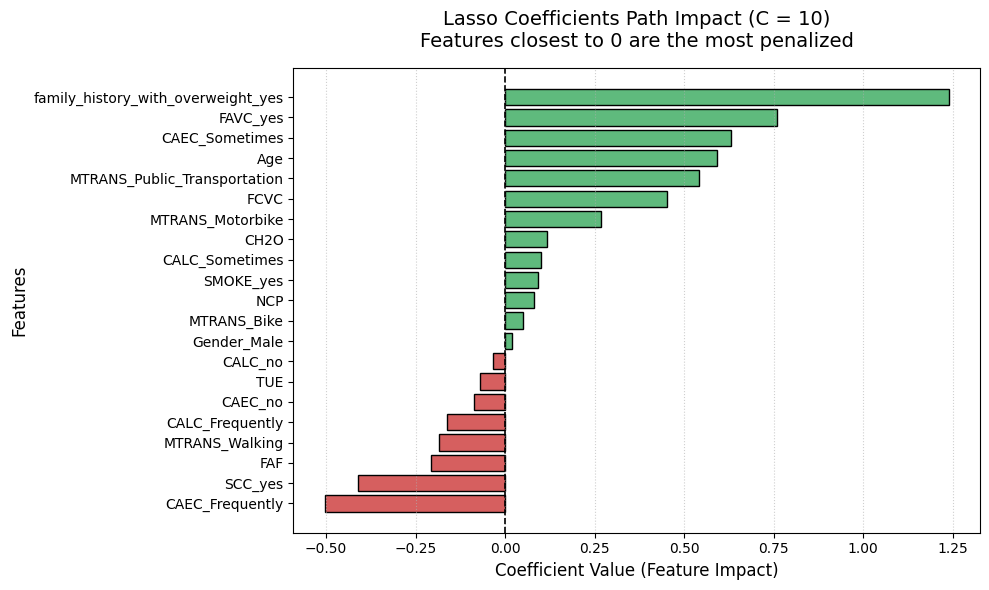

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

lr_step = model_lasso.named_steps["logisticregression"]
coefficients = lr_step.coef_[0]
feature_names = X_train.columns

coef_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Coefficient": coefficients,
        "Absolute_Coef": np.abs(coefficients),
    }
)

# order coefficients from most important to less important
coef_df = coef_df.sort_values(by="Absolute_Coef", ascending=False).reset_index(
    drop=True
)

kept_features = coef_df[coef_df["Coefficient"] != 0]
eliminated_features = coef_df[coef_df["Coefficient"] == 0]

best_C = (
    cv_lasso.best_params_.get("C")
    if "C" in cv_lasso.best_params_
    else cv_lasso.best_params_.get("logisticregression__C")
)


# PLOTTING

plt.figure(figsize=(10, 6))

# sort feature by coefficient
plot_df = coef_df.sort_values(by="Coefficient", ascending=True)

colors = ["#d65f5f" if c < 0 else "#5fba7d" for c in plot_df["Coefficient"]]
plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors, edgecolor="black")

plt.axvline(0, color="black", linestyle="--", linewidth=1.2)

plt.title(
    f"Lasso Coefficients Path Impact (C = {best_C})\nFeatures closest to 0 are the most penalized",
    fontsize=14,
    pad=15,
)
plt.xlabel("Coefficient Value (Feature Impact)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Model Diagnostics

Unregularized logistic regression and Lasso logistic regresion show clear signs of bias (curves converge fastly and tightly but at low accuracies). Since the simple logistic model was already biased the lasso regression was not useful. Talking about the ridge regression it is biased at a pathological level due to coefficients shrinkage. On the other hand random forest's learning curve looks overfitted (high variance) but not to a pathological extent, thanks to depth limitations imposed previously.

We would remove and not consider logistic regression regularizations.

Because it evaluates true generalizability, showing how robustly the patterns picked up during training apply to separate patients' profiles.


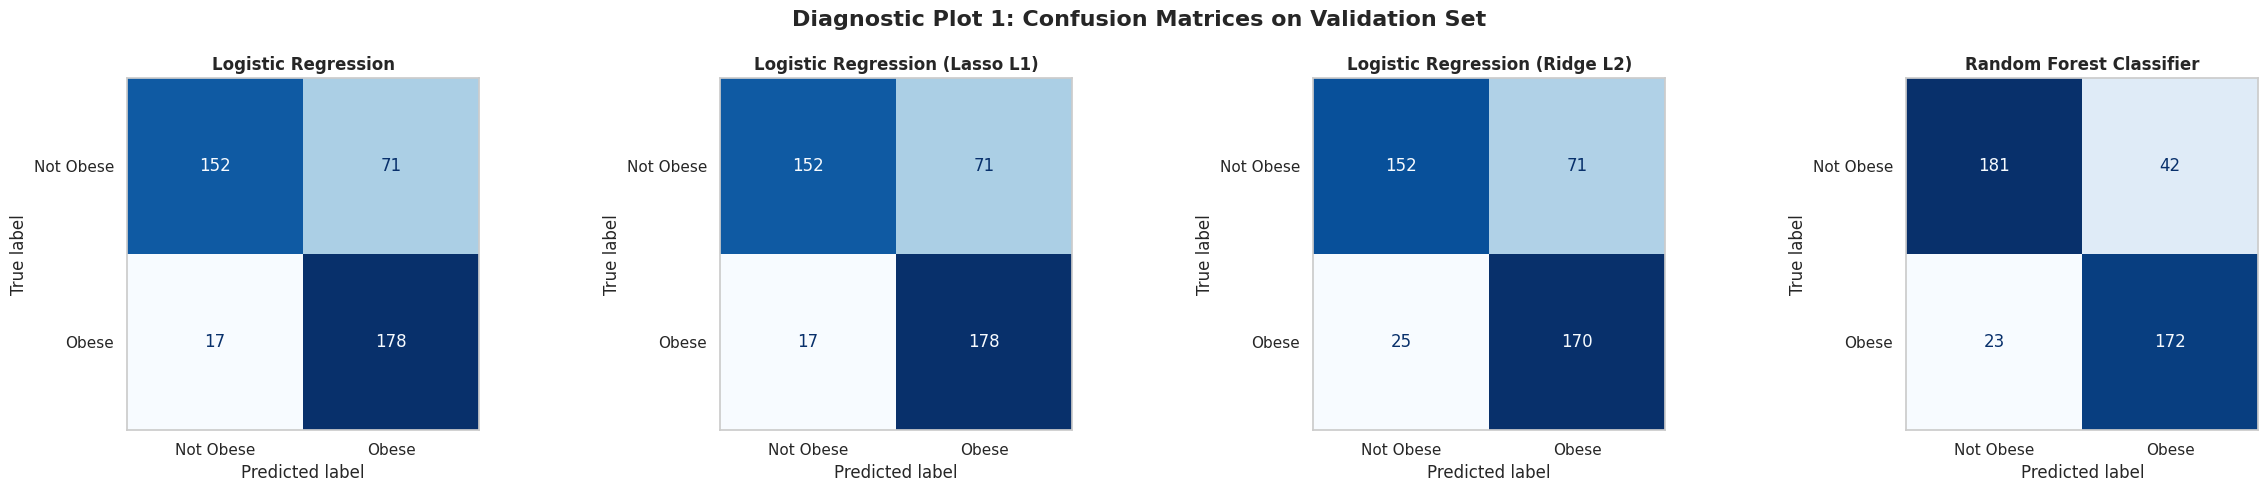

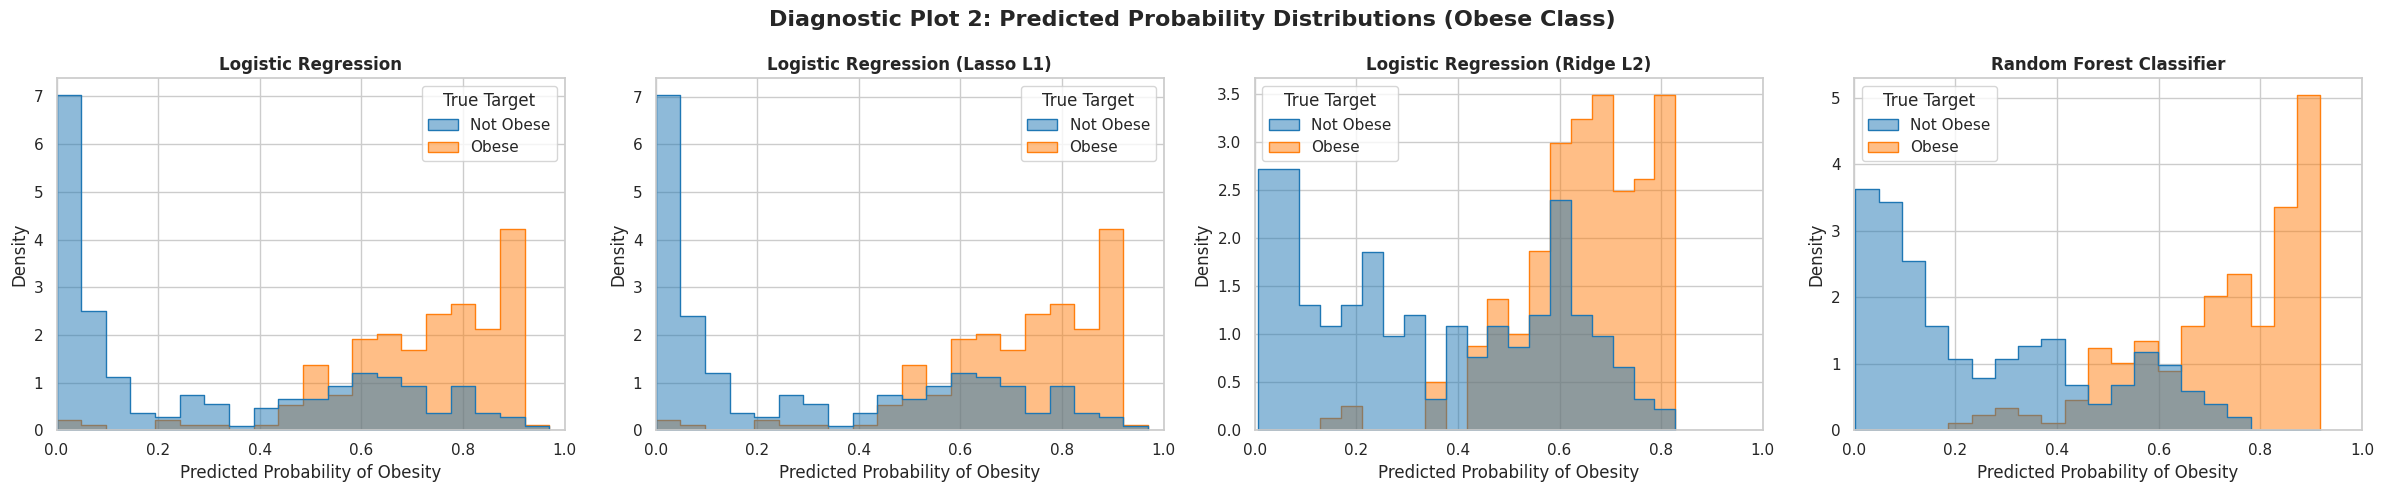

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

# baseline has no probabilistic output, skip it here
models_to_plot = {name: model for name, model in best_models.items() if "Baseline" not in name}
num_models = len(models_to_plot)

# confusion matrices on the validation set
fig, axes = plt.subplots(1, num_models, figsize=(6 * num_models, 5))
fig.suptitle(
    "Diagnostic Plot 1: Confusion Matrices on Validation Set", fontsize=16, fontweight="bold"
)

# axes isn't a list when there's only one subplot
if num_models == 1:
    axes = [axes]

for i, (name, model) in enumerate(models_to_plot.items()):
    y_val_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_val_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Obese", "Obese"])
    disp.plot(ax=axes[i], cmap="Blues", values_format="d", colorbar=False)
    axes[i].set_title(name, fontsize=12, fontweight="bold")
    axes[i].grid(False)

plt.tight_layout()
plt.show()

# predicted probability distributions for the obese class
fig, axes = plt.subplots(1, num_models, figsize=(6 * num_models, 5))
fig.suptitle(
    "Diagnostic Plot 2: Predicted Probability Distributions (Obese Class)",
    fontsize=16,
    fontweight="bold",
)

if num_models == 1:
    axes = [axes]

for i, (name, model) in enumerate(models_to_plot.items()):
    y_val_proba = model.predict_proba(X_val)[:, 1]

    proba_df = pd.DataFrame(
        {"Probability": y_val_proba, "True Target": y_val.map({0: "Not Obese", 1: "Obese"})}
    )

    sns.histplot(
        data=proba_df,
        x="Probability",
        hue="True Target",
        element="step",
        stat="density",
        common_norm=False,
        alpha=0.5,
        bins=20,
        ax=axes[i],
        palette={"Not Obese": "#1f77b4", "Obese": "#ff7f0e"},
    )

    axes[i].set_title(name, fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Predicted Probability of Obesity")
    axes[i].set_xlim(0, 1)

plt.tight_layout()
plt.show()

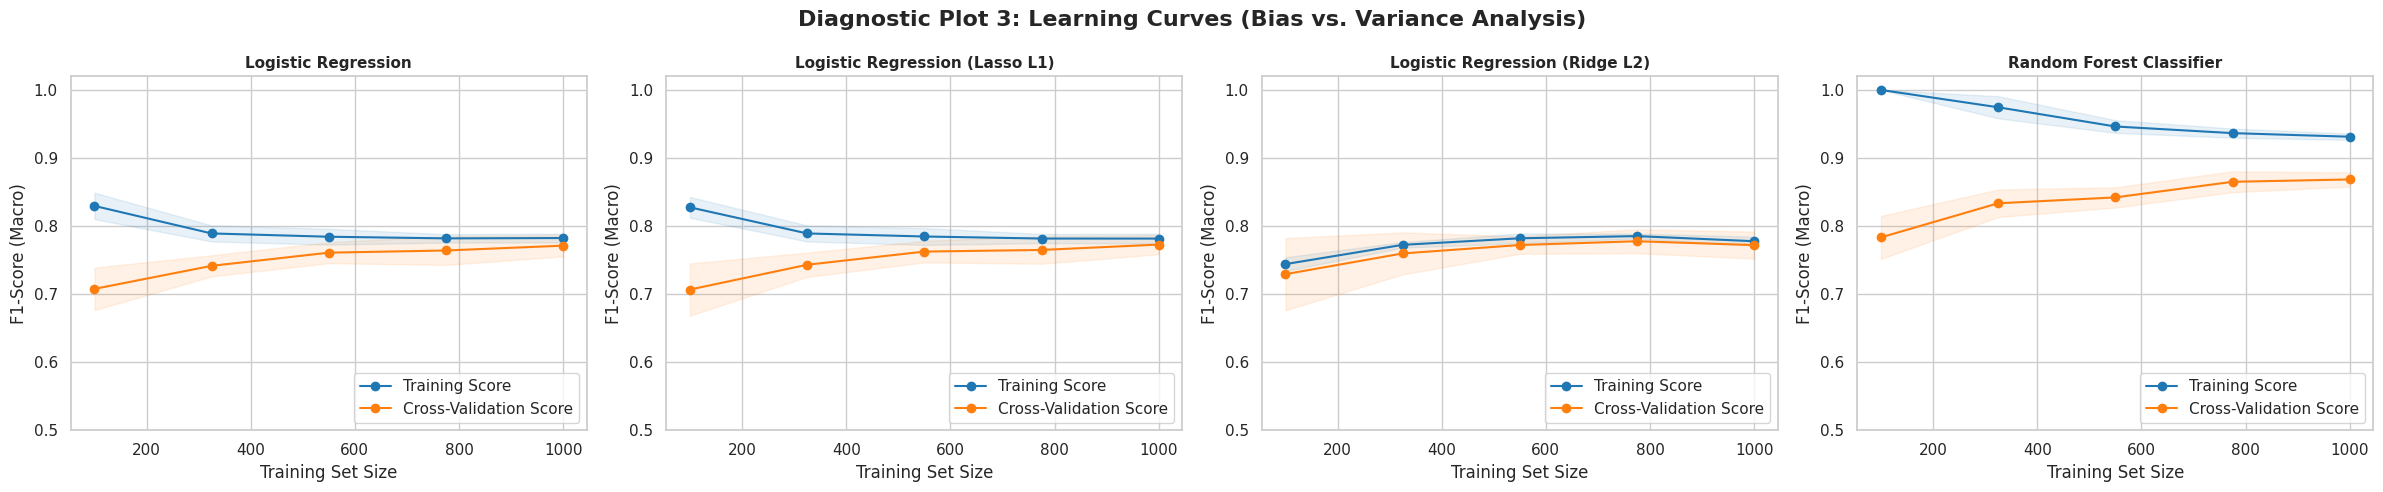

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# skip the baseline, not worth a learning curve
models_for_curves = {
    name: model for name, model in best_models.items() if "Baseline" not in name
}
num_models = len(models_for_curves)

fig, axes = plt.subplots(1, num_models, figsize=(6 * num_models, 5))
fig.suptitle(
    "Diagnostic Plot 3: Learning Curves (Bias vs. Variance Analysis)",
    fontsize=16,
    fontweight="bold",
)

# axes isn't a list when there's only one subplot
if num_models == 1:
    axes = [axes]

for i, (name, model) in enumerate(models_for_curves.items()):

    train_sizes, train_scores, val_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=5,
        scoring="f1_macro",
        n_jobs=-1,
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[i].plot(train_sizes, train_mean, "o-", color="#1f77b4", label="Training Score")
    axes[i].fill_between(
        train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="#1f77b4"
    )

    axes[i].plot(train_sizes, val_mean, "o-", color="#ff7f0e", label="Cross-Validation Score")
    axes[i].fill_between(
        train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color="#ff7f0e"
    )

    axes[i].set_title(name, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Training Set Size")
    axes[i].set_ylabel("F1-Score (Macro)")
    axes[i].set_ylim(0.5, 1.02)
    axes[i].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Choosing the final model

Choose one final model.

Your choice must be based on:

- validation performance;
- diagnostic plots;
- interpretability;
- biological question;
- risk of overfitting;
- comparison to the baseline.

You may choose a simpler model even if a complex model performs slightly better, if the simpler model is more interpretable and the performance difference is small.

<br>

----
----
----

<br>

We choose ***RANDOM FOREST BINARY CLASSIFIER***  because, across all the models we have fit, it's the one with the highest evaluation metrics. The high F1 score (armonic mean between precision and recall) shows that the model is really reliable. Moreover, thanks to the analysis of the feature importance we can also state that the model is interpretable, and that the interpretation has biological meaning (e.g. the high importance of family history). The only drawback of this model is the high variance exibited in the training curves; in spite of this we do not believe we are in front of a severely overfitted model.

<br>

----

<br>

Here we report the reasons why the other considered models have not been choosen.

* *Majority predictor:*  As we expected, its performances were really low.

* *Logistics regressions:*  As we have previously seen, logistic regression showed bias issues when facing our biological prediction problem; and the implementation of regularization exacerbated this situation. We believe that the cause of this is to be addressed to the intimately <u>non-linear nature of our biological question</u>; that the logistic regression's (rigid and therefore biased) linear hyperplane failed to dissect.

  * It is our belief that the implementation of other advanced models such as binary classification neural networks or non-linear (kernel trick) SVM would have better tackled this non-lineariy.

<br>

----

<br>

Ultimately, our model choice prioritizes performance over robustness and compromises with a perceptible amount of variance. We will soon see if this compromise will hold against the test set.

<br>

----

# Final model evaluation

RANDOM FOREST FINAL EVALUATION:
  Train      | Accuracy: 0.9145  | F1-Score (Macro): 0.9143
  Validation | Accuracy: 0.8445  | F1-Score (Macro): 0.8444
  Test       | Accuracy: 0.8541  | F1-Score (Macro): 0.8539


CONFUSION MATRIX:


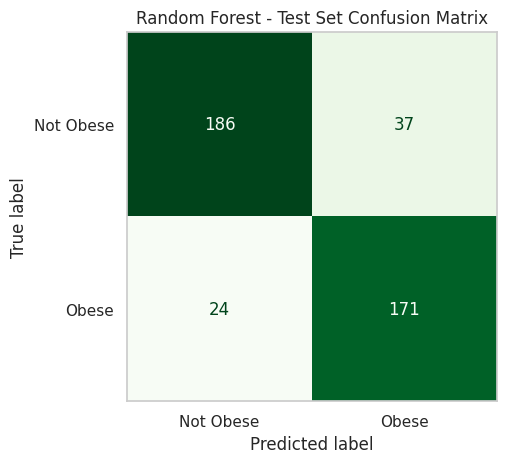



★EVALUATION METRICS★
══════════════════════════════
accuracy: 0.854066985645933
──────────────────────────────
precision: 0.8221153846153846
──────────────────────────────
recall: 0.8769230769230769
──────────────────────────────
F1: 0.8486352357320099
──────────────────────────────
confusion_matrix: [[186  37]
 [ 24 171]]
──────────────────────────────
roc_auc: 0.9323904794756812
──────────────────────────────


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


final_rf_model = best_models["Random Forest Classifier"]

train_acc_rf = round(accuracy_score(y_train, y_train_pred_rf), 4)
val_acc_rf = round(accuracy_score(y_val, y_val_pred_rf), 4)

y_test_pred_rf = final_rf_model.predict(X_test)
y_test_proba_rf = final_rf_model.predict_proba(X_test)


test_acc_rf = round(accuracy_score(y_test, y_test_pred_rf), 4)
test_f1_rf = round(f1_score(y_test, y_test_pred_rf, average="macro"), 4)

print("==================================================")
print(f"RANDOM FOREST FINAL EVALUATION:")
print(f"  Train      | Accuracy: {train_acc_rf}  | F1-Score (Macro): {model_results[-1]['Train F1-Macro']}")
print(f"  Validation | Accuracy: {val_acc_rf}  | F1-Score (Macro): {model_results[-1]['Val F1-Macro']}")
print(f"  Test       | Accuracy: {test_acc_rf}  | F1-Score (Macro): {test_f1_rf}")
print("==================================================")
print("\n")
print("CONFUSION MATRIX:")
cm = confusion_matrix(y_test, y_test_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Obese", "Obese"])
disp.plot(cmap=plt.cm.Greens, colorbar=False)
plt.title("Random Forest - Test Set Confusion Matrix")
disp.ax_.grid(False)
plt.show()
print("\n")
print("\u2605EVALUATION METRICS\u2605")
print("\u2550" * 30)
for m, v in classification_metrics(y_test, y_test_pred_rf, y_test_proba_rf).items():
    print(f"{m}: {v}")
    print("\u2500" * 30)


Validation and test performance are almost the same, which is a good sign.

AIf test performance would have been worse than validation ones, it would probably be due to the fact that hyperparameter tuning was made with the validation set.

We would trust this model for a biological conclusion because the evaluation metrics are consistent and they confirm that we are looking at a reliable model that, in spite of the previously observed variance, has also appreciable generalization capabilities.



# Biological Interpretation

In [ ]:
X_behavioral = X.drop(columns=["Height", "Weight"])
X_behavioral.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2087 entries, 0 to 2110
Data columns (total 21 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 2087 non-null   float64
 1   FCVC                                2087 non-null   float64
 2   NCP                                 2087 non-null   float64
 3   CH2O                                2087 non-null   float64
 4   FAF                                 2087 non-null   float64
 5   TUE                                 2087 non-null   float64
 6   Gender_Male                         2087 non-null   bool   
 7   family_history_with_overweight_yes  2087 non-null   bool   
 8   FAVC_yes                            2087 non-null   bool   
 9   CAEC_Frequently                     2087 non-null   bool   
 10  CAEC_Sometimes                      2087 non-null   bool   
 11  CAEC_no                             2087 non-nul

LOGISTIC REGRESSION COEFFICIENTS (Magnitude Order)

Unregularized (Plain):
  family_history_with_overweight_yes: 1.2432
  FAVC_yes: 0.7608
  CAEC_Sometimes: 0.6343
  Age: 0.5921
  MTRANS_Public_Transportation: 0.5435
  CAEC_Frequently: -0.5041
  FCVC: 0.4540
  SCC_yes: -0.4120
  MTRANS_Motorbike: 0.2710
  FAF: -0.2086
  MTRANS_Walking: -0.1862
  CALC_Frequently: -0.1652
  CH2O: 0.1168
  CALC_Sometimes: 0.0979
  SMOKE_yes: 0.0938
  CAEC_no: -0.0877
  NCP: 0.0802
  TUE: -0.0702
  MTRANS_Bike: 0.0516
  CALC_no: -0.0377
  Gender_Male: 0.0217

Lasso (L1):
  family_history_with_overweight_yes: 1.2396
  FAVC_yes: 0.7592
  CAEC_Sometimes: 0.6323
  Age: 0.5908
  MTRANS_Public_Transportation: 0.5420
  CAEC_Frequently: -0.5039
  FCVC: 0.4530
  SCC_yes: -0.4097
  MTRANS_Motorbike: 0.2694
  FAF: -0.2077
  MTRANS_Walking: -0.1856
  CALC_Frequently: -0.1632
  CH2O: 0.1159
  CALC_Sometimes: 0.1016
  SMOKE_yes: 0.0928
  CAEC_no: -0.0873
  NCP: 0.0796
  TUE: -0.0696
  MTRANS_Bike: 0.0489
  CALC_no: -0.0

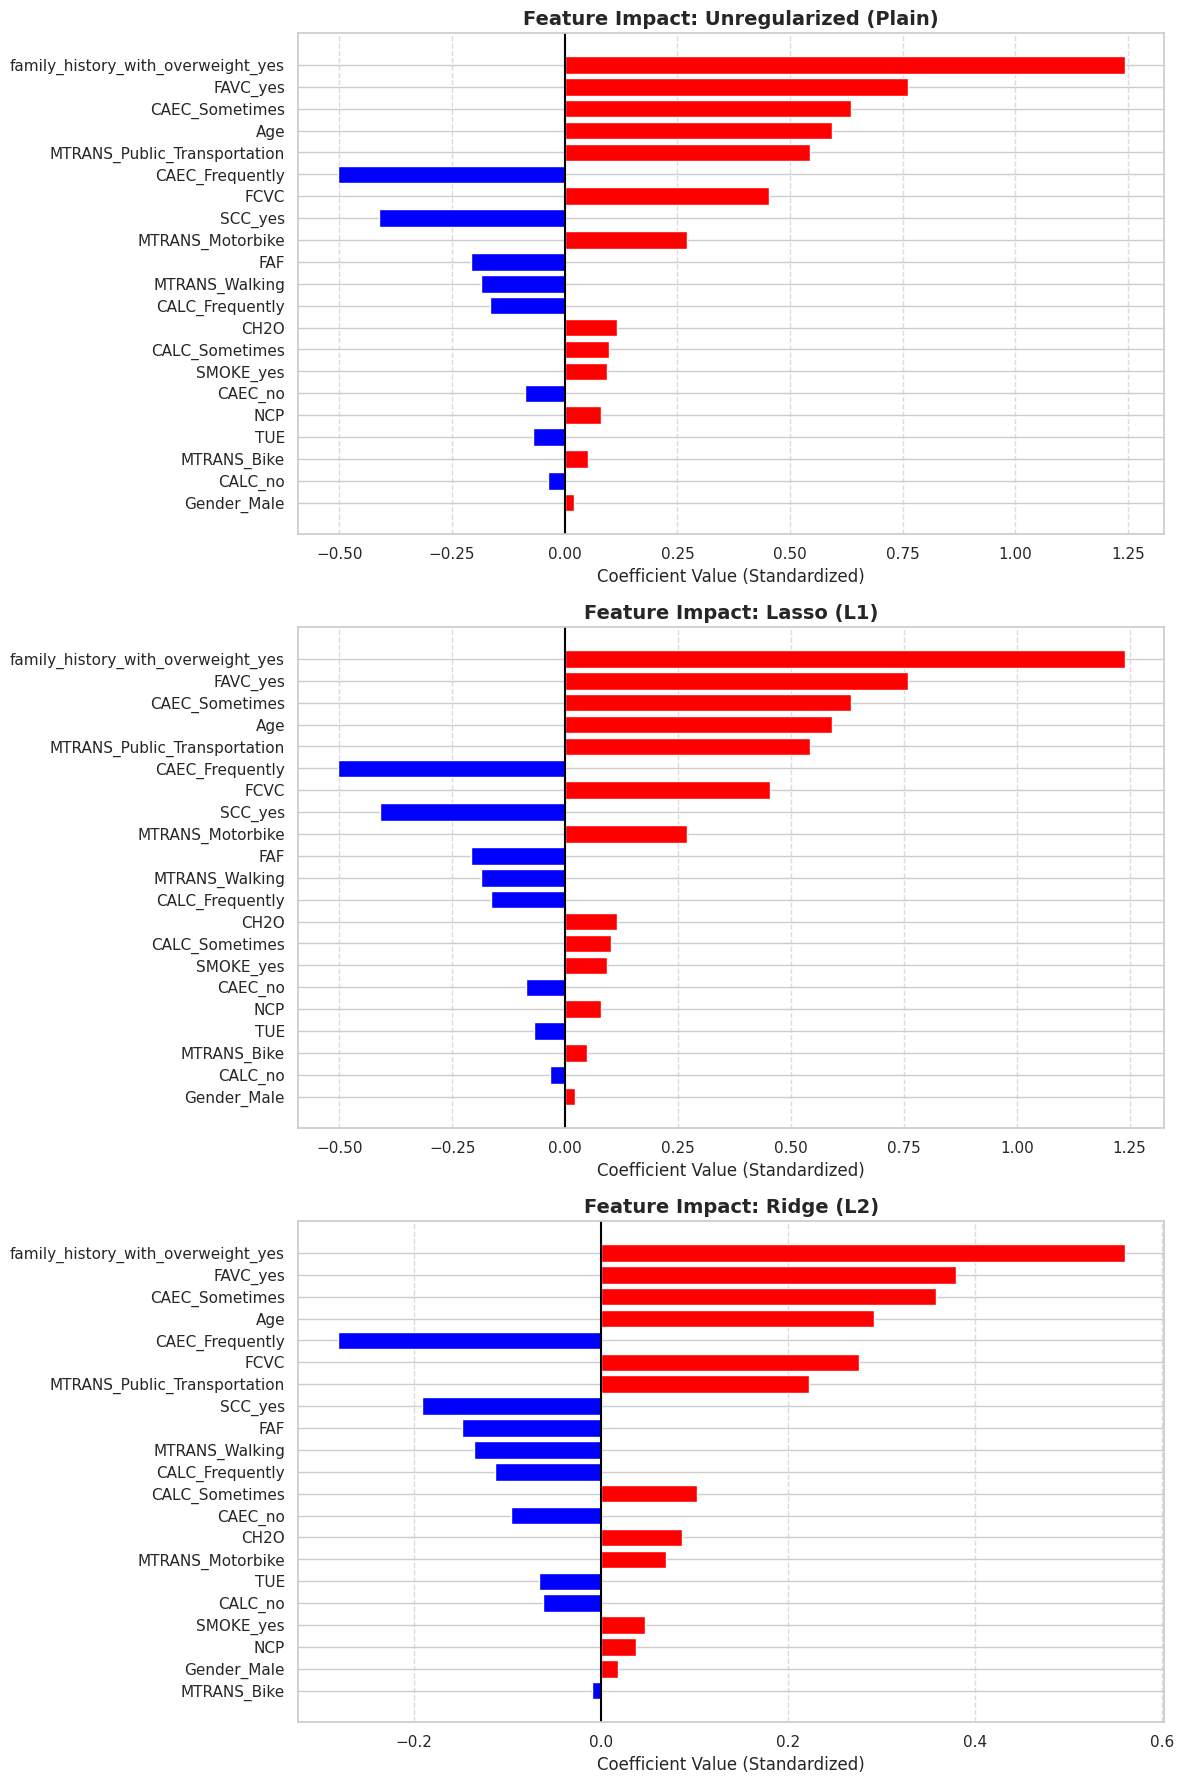

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


logreg_models = {
    "Unregularized (Plain)": best_models["Logistic Regression"],
    "Lasso (L1)": best_models["Logistic Regression (Lasso L1)"],
    "Ridge (L2)": best_models["Logistic Regression (Ridge L2)"]
}

features = X_train.columns


fig, axes = plt.subplots(3, 1, figsize=(12, 18))

print("==================================================")
print("LOGISTIC REGRESSION COEFFICIENTS (Magnitude Order)")
print("==================================================")

for ax, (model_name, model_pipeline) in zip(axes, logreg_models.items()):

    coefs = model_pipeline.named_steps["logisticregression"].coef_[0]


    abs_coefs = np.abs(coefs)


    mag_indices_print = np.argsort(abs_coefs)[::-1]


    print(f"\n{model_name}:")
    for i in mag_indices_print:
        if model_name == "Lasso (L1)" and coefs[i] == 0:
            print(f"  {features[i]}: {coefs[i]:.4f} (ELIMINATA)")
        else:
            print(f"  {features[i]}: {coefs[i]:.4f}")


    mag_indices_plot = np.argsort(abs_coefs)


    sorted_features = features[mag_indices_plot]
    sorted_coefs = coefs[mag_indices_plot]


    colors = ['blue' if c < 0 else 'red' for c in sorted_coefs]


    ax.barh(sorted_features, sorted_coefs, color=colors)

    ax.axvline(0, color='black', linewidth=1.5)

    ax.set_title(f"Feature Impact: {model_name}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Coefficient Value (Standardized)")
    ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Feature Importances:
family_history_with_overweight_yes: 0.1675
Age: 0.1492
NCP: 0.1096
CAEC_Sometimes: 0.0853
FCVC: 0.0850
CH2O: 0.0780
FAF: 0.0717
TUE: 0.0602
FAVC_yes: 0.0540
CAEC_Frequently: 0.0408
CALC_Sometimes: 0.0243
MTRANS_Public_Transportation: 0.0179
Gender_Male: 0.0156
CALC_no: 0.0124
SCC_yes: 0.0079
CALC_Frequently: 0.0075
MTRANS_Walking: 0.0051
SMOKE_yes: 0.0036
CAEC_no: 0.0029
MTRANS_Motorbike: 0.0014
MTRANS_Bike: 0.0003


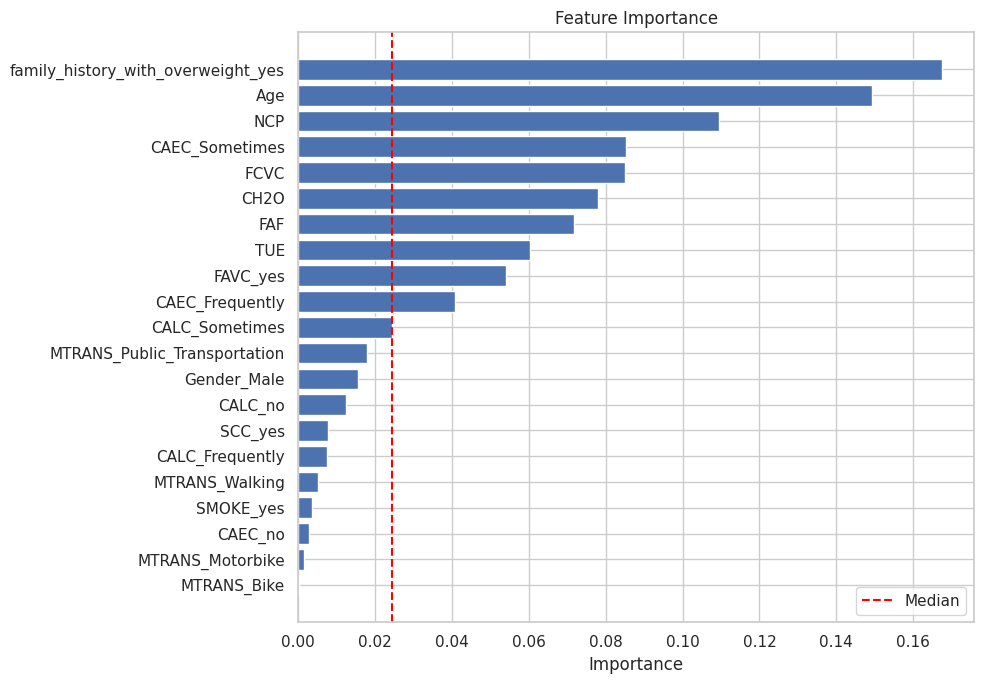

In [ ]:
#  importances from the model
importances = model_rf.named_steps["randomforestclassifier"].feature_importances_
features = X_train.columns

# Sort and print
indices = importances.argsort()[::-1]

print("Feature Importances:")
for i in indices:
    print(f"{features[i]}: {importances[i]:.4f}")

# Plot
plt.figure(figsize=(10, 7))
plt.barh(features[indices][::-1], importances[indices][::-1])
median_val = np.median(importances)
plt.axvline(median_val, color="red", linestyle="--", label="Median")

plt.xlabel("Importance")
plt.title("Feature Importance")
plt.legend()
plt.tight_layout()
plt.show()


----

As said when the dataset was downloaded, the variables are encoded with mixed type choices, and this has to be kept in mind when proposing biological interpretations.

#### Logistic Regression Classification

Both the unregularized logistic regression and the regularized ones show almost identical top feature predictors. On the other hand there is variation with respect to the regularization method for the least important features.
* Best positive obesity predictors:
  * Family history with obesity
    * This strongly highlights genetic and educational fundamental importance in obesity prediction
  * Frequency of high caloric food assumption
    * The accumulation of calories through lipids damages biochemical balances
  * Food between meals: SOMETIMES
    * This probably indicates "having snacks" during the day, which might correlate with insuline inefficiency and high caloric assumption
  * Age
    * The capability of the body to deal with metabolic stress decreases with aging
* Best negative obesity predictors:
  * Food between meals: FREQUENTLY
    * This was counterintuitive at the start, but we interpret this as an indicator of athletes with high need for calories or people with extremely high metabolic rates; both protective factors against obesity
  * To monitor calories assumption
    * A strong risk decreasing factor since it shows a person actively involved in food income monitoring
  * Frequency of physical activity
    * Physical activity both via fat tissue degradation and muscle tissue (a strong glycemic regulator) hypertrophy protects against obesity
  * Walking as a means of transport
    * Not using any mean of transport not only shows an higher basal degree of physical activity, but might also correlate with living in a human-scale low-stress environment, since cortisol is proven to be a cause of obesity

Moreover we are puzzled by the negative correlation of high alcohol assumption and positive correlation of medium alcohol assumption, we suspect this might be selection bias (spourious correlation), since we cannot find a reasonable interpretation. Therefore we investigate further:



In [ ]:
import pandas as pd

df_temp = pd.DataFrame({
    'Alcohol_Consumption': X_obesity_raw['CALC'],
    'Is_Obese': y_obesity_binary
})


counts_tab = pd.crosstab(df_temp['Alcohol_Consumption'], df_temp['Is_Obese'])


pct_tab = pd.crosstab(df_temp['Alcohol_Consumption'], df_temp['Is_Obese'], normalize='index') * 100


print("═" * 78)
print("\u25ba FULL OBESITY DISTRIBUTION & COUNTS BY ALCOHOL CONSUMPTION (CALC) \u25c4")
print("═" * 78)
print(f"  Category        │ {'Obese (Class 1)'.center(25)} │ {'Not Obese (Class 0)'.center(25)} │")
print("─" * 78)


for category in counts_tab.index:

    count_0 = counts_tab.loc[category, 0]
    count_1 = counts_tab.loc[category, 1]


    pct_0 = pct_tab.loc[category, 0]
    pct_1 = pct_tab.loc[category, 1]


    obese_str = f"{count_1:4d} ({pct_1:5.1f}%)"
    not_obese_str = f"{count_0:4d} ({pct_0:5.1f}%)"


    print(f"  {category.ljust(15)} │ {obese_str.center(25)} │ {not_obese_str.center(25)} │")

print("═" * 78)

══════════════════════════════════════════════════════════════════════════════
► FULL OBESITY DISTRIBUTION & COUNTS BY ALCOHOL CONSUMPTION (CALC) ◄
══════════════════════════════════════════════════════════════════════════════
  Category        │      Obese (Class 1)      │    Not Obese (Class 0)    │
──────────────────────────────────────────────────────────────────────────────
  Always          │          0 (  0.0%)       │          1 (100.0%)       │
  Frequently      │         16 ( 22.9%)       │         54 ( 77.1%)       │
  Sometimes       │        719 ( 51.3%)       │        682 ( 48.7%)       │
  no              │        237 ( 37.1%)       │        402 ( 62.9%)       │
══════════════════════════════════════════════════════════════════════════════


This table does not uniquely state spourious correlation, but having only 1 and 70 observation for "Always" and "Frequently" makes us almost sure the regressions are just memorizing biologically meaningless casual correlations in this two cases.
In more formal analysis it would be advisable to check for single observation or really low observation feature occurencies in all the dataset before performing the analysis, in order to preventively protect the algorithms from dealing with possible sporious correlation.

#### Random forest classification

Unlike logistic regression, random forest does not allow us to see festures' direction, but only their importance: the model is therefore to be considered less interpretable (even if there are some advanced packages and methematical tools to unveil the mean direction the parameters are pushing to in random forest).

The most important features in random forest are quite similar to the logist model ones (ordered by absolute value magnitude); the main difference is that water consumption and number of meals in a day gain some importance, but the overall interpretation of "healthy lifestyle" indicators remains clear.

#### About behavioral self-reporting
Most of our considered features come from self reportage about patient lifestyle: this introduces a strong psychological bias in the sampling that introduces non-biological confundants and noise. Consequently, the model learning paradigm (and therefore interpretation) would have to be considered
* if the patient thinks to do X, then Y

and not
* if the patient does X, then Y

##### About causality
The study captures a single snapshot in time and can only unveil correlation with the target variable, not causation (or protection). Our biological interpretations followed a causal mindset but that is not necessarily the case; for instance, walking as a means of transport might not have any protective effect at all against obesity, it could just be that obese individuals, due to reduced physical capabilities, walk less.

# LIMITATIONS



* ### Synthetic data
A significant portion of the dataset consists of synthetically generated instances introduced via oversampling techniques to balance the target classes. While beneficial for stabilizing model training, this process introduces fractional, continuous values to inherently discrete and ordinal variables (e.g., FCVC and NCP). From a rigorous perspective, this artificial smoothing eliminates the stochastic noise naturally present in clinical data, leading to over-optimistic performance metrics (Accuracy and F1-Score) that may not hold in real-world deployments.

* ### Causal inference
A time-comparison study would have permitted to interpret the models inferring on causality.

* ### Binary Compounding of a Continuous Spectrum
Obesity is physiologically defined across a continuous Body Mass Index (BMI) gradient. By collapsing the multi-class categorization into a rigid binary target (Obese vs. Not Obese), the models treat borderline profiles (e.g., a BMI of 29.9 versus 30.1) as fundamentally distinct classes. This thresholding masks subtle metabolic transitions and reduces the granularity of the clinical prediction.

* ### Suboptimal Handling of Ordinal Features
The pipeline treats text-based ordinal features (such as CALC for alcohol intake and CAEC for eating between meals) via One-Hot Encoding (Dummy Variables). While mathematically compatible with linear and tree-based models, this approach explicitly discards the natural rank and progression of the categories (e.g., "No" $\rightarrow$ "Sometimes" $\rightarrow$ "Frequently"). Additionally, preserving artificially-generated continuous fractions as standard numerical floats might force models to evaluate illogical data splits (such as eating 2.43 meals per day).

* ### Geographic and Demographic Constraints
The sampled individuals often share geographycal, ethnical and demographic background.

* ### Lack of model implementation
Even if the random forest classification model has proven to be valid and apt to the situation, a discrete amount of other models, such as neural network binary classificators, or non-linear SVM, or K-NN, could be implemented, tested, and compared.



